### Lab Sheet 01 – Sentiment Analysis Using Traditional Machine Learning

**Module:** PUSL 3205 – Large Language Models and Generative AI  
**Topic:** Text Preprocessing, Bag of Words, TF-IDF and Machine Learning  
**Dataset:** UCI Sentiment Labelled Sentences

##### Objective
Practice basic Natural Language Processing (NLP), text preprocessing, feature extraction and sentiment classification using traditional machine learning.



##### 1. Import Libraries
Import the libraries required for data handling, preprocessing, visualisation, feature extraction, model training and evaluation.

In [1]:

# %pip install pandas numpy nltk scikit-learn matplotlib seaborn requests

import re
import zipfile
import requests
from io import BytesIO
from pathlib import PurePosixPath
from collections import Counter

import numpy as np
import pandas as pd
import nltk
from nltk.corpus import stopwords

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

import joblib
import os

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

nltk.download("stopwords", quiet=True)

print("Libraries imported successfully.")

Libraries imported successfully.


##### 2. Download and Load the Dataset
The dataset contains three labelled review files: Amazon, IMDb and Yelp. The following cell downloads the official UCI ZIP archive and combines the three files into one DataFrame.

In [2]:
DATASET_URL = (
    "https://archive.ics.uci.edu/static/public/331/"
    "sentiment+labelled+sentences.zip"
)

response = requests.get(DATASET_URL, timeout=60)
response.raise_for_status()

valid_files = {
    "amazon_cells_labelled.txt",
    "imdb_labelled.txt",
    "yelp_labelled.txt"
}

dataset_zip = zipfile.ZipFile(BytesIO(response.content))
dataframes = []

for filename in dataset_zip.namelist():
    base_name = PurePosixPath(filename).name

    if base_name not in valid_files:
        continue

    with dataset_zip.open(filename) as file:
        temp_df = pd.read_csv(
            file,
            sep="\\t",
            header=None,
            names=["sentence", "label"],
            encoding="latin-1",
            engine="python"
        )
        temp_df["domain"] = base_name.replace("_labelled.txt", "")
        dataframes.append(temp_df)

if not dataframes:
    raise ValueError("The expected UCI dataset files were not found.")

df = pd.concat(dataframes, ignore_index=True)
df["label"] = pd.to_numeric(df["label"], errors="coerce")
df = df.dropna(subset=["sentence", "label"]).copy()
df["label"] = df["label"].astype(int)
df = df.reset_index(drop=True)

print("Dataset downloaded and loaded successfully.")
print("Dataset shape:", df.shape)
display(df.head())

Dataset downloaded and loaded successfully.
Dataset shape: (3000, 3)


,sentence,label,domain
0,So there is no way for me to plug it in here i...,0,amazon_cells
1,"Good case, Excellent value.",1,amazon_cells
2,Great for the jawbone.,1,amazon_cells
3,Tied to charger for conversations lasting more...,0,amazon_cells
4,The mic is great.,1,amazon_cells


##### 3. Inspect the Dataset
Inspect the number of records, columns, missing values, duplicates, sentiment labels and review domains.

In [3]:
print("DATASET INFORMATION")
print("=" * 55)
print("Shape:", df.shape)
df.info()

print("\\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\\nDuplicate sentence-label pairs:")
print(df.duplicated(subset=["sentence", "label"]).sum())

print("\\nSentiment distribution (0 = Negative, 1 = Positive):")
display(df["label"].value_counts().sort_index().rename(
    index={0: "Negative", 1: "Positive"}
).to_frame("Count"))

print("\\nRecords by domain:")
display(df["domain"].value_counts().to_frame("Count"))

display(df.sample(min(10, len(df)), random_state=RANDOM_STATE))

DATASET INFORMATION
Shape: (3000, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   sentence  3000 non-null   object
 1   label     3000 non-null   int64 
 2   domain    3000 non-null   object
dtypes: int64(1), object(2)
memory usage: 70.4+ KB
\nMissing values:


,Missing Values
sentence,0
label,0
domain,0


\nDuplicate sentence-label pairs:
17
\nSentiment distribution (0 = Negative, 1 = Positive):


,Count
label,
Negative,1500
Positive,1500


\nRecords by domain:


,Count
domain,
amazon_cells,1000
imdb,1000
yelp,1000


,sentence,label,domain
1801,Avoid at ALL costs!,0,imdb
1190,"Garbo, who showed right off the bat that her t...",1,imdb
1817,You will leave the theater wanting to go out a...,1,imdb
251,O my gosh the best phone I have ever had.,1,amazon_cells
2505,I would not recommend this place.,0,yelp
1117,Then scene where they debated whether or not t...,0,imdb
1411,Her role was played well.,1,imdb
2113,"Nice, spicy and tender.",1,yelp
408,Plantronics Bluetooth Excelent Buy.,1,amazon_cells
2579,"As for the service: I'm a fan, because it's qu...",1,yelp


##### 4. Clean the Dataset
Remove missing records, invalid labels, duplicate sentence-label pairs and empty sentences.

In [4]:
df_clean = df.copy()
initial_count = len(df_clean)

df_clean = df_clean.dropna(subset=["sentence", "label"])
df_clean["sentence"] = df_clean["sentence"].astype(str)
df_clean["label"] = df_clean["label"].astype(int)
df_clean = df_clean[df_clean["label"].isin([0, 1])]
df_clean = df_clean.drop_duplicates(subset=["sentence", "label"])
df_clean = df_clean[df_clean["sentence"].str.strip().ne("")]
df_clean = df_clean.reset_index(drop=True)

print("Initial records:", initial_count)
print("Records after cleaning:", len(df_clean))
print("Removed records:", initial_count - len(df_clean))
print("Remaining missing values:", int(df_clean.isnull().sum().sum()))
display(df_clean.head())

Initial records: 3000
Records after cleaning: 2983
Removed records: 17
Remaining missing values: 0


,sentence,label,domain
0,So there is no way for me to plug it in here i...,0,amazon_cells
1,"Good case, Excellent value.",1,amazon_cells
2,Great for the jawbone.,1,amazon_cells
3,Tied to charger for conversations lasting more...,0,amazon_cells
4,The mic is great.,1,amazon_cells


##### 5. Text Preprocessing
Create a `clean_text` column. Text is converted to lowercase, URLs and HTML tags are removed, punctuation and unnecessary characters are removed, and extra whitespace is normalised.

In [5]:
def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"http\\S+|www\\S+", " ", text)
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"[^a-z0-9\\s]", " ", text)
    text = re.sub(r"\\s+", " ", text)
    return text.strip()

df_clean["clean_text"] = df_clean["sentence"].apply(preprocess_text)
df_clean = df_clean[df_clean["clean_text"].str.strip().ne("")].reset_index(drop=True)

print("Text preprocessing completed.")
display(df_clean[["sentence", "clean_text", "label"]].sample(
    min(15, len(df_clean)), random_state=RANDOM_STATE
))

Text preprocessing completed.


,sentence,clean_text,label
2410,We've tried to like this place but after 10+ t...,we ve tried to like this place but after 10 t...,0
1547,The script is a big flawed mess.,the script is a big flawed mess,0
881,It was that loud.Glad to say that the Plantron...,it was that loud glad to say that the plantron...,1
331,The reception is excellent!,the reception is excellent,1
1837,Now imagine that every single one of those dec...,now imagine that every single one of those dec...,0
1242,The soundtrack sucked.,the soundtrack sucked,0
678,This product is clearly not ready for prime ti...,this product is clearly not ready for prime ti...,0
1216,"He can bore you to pieces, and kill the moment...",he can bore you to pieces and kill the moment...,0
1029,This was a flick doomed from its conception.,this was a flick doomed from its conception,0
2024,"Poor service, the waiter made me feel like I w...",poor service the waiter made me feel like i w...,0


##### 6. Explore the Text Data
###### 6.1 Sentiment Distribution
Visualise the number of positive and negative sentences.

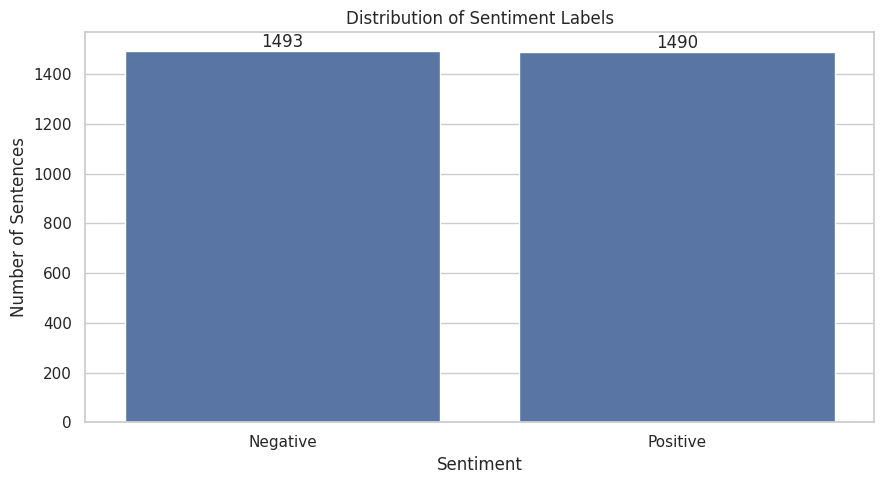

,Count
label,
Negative,1493
Positive,1490


In [6]:
sentiment_counts = df_clean["label"].value_counts().reindex([0, 1], fill_value=0)
sentiment_plot = sentiment_counts.rename(index={0: "Negative", 1: "Positive"})

ax = sns.barplot(x=sentiment_plot.index, y=sentiment_plot.values)
ax.set_title("Distribution of Sentiment Labels")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Number of Sentences")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()

display(sentiment_plot.to_frame("Count"))

###### 6.2 Sentiment by Review Domain
Compare positive and negative reviews across Amazon, IMDb and Yelp.

,Negative,Positive
domain,,
amazon_cells,497,493
imdb,499,498
yelp,497,499


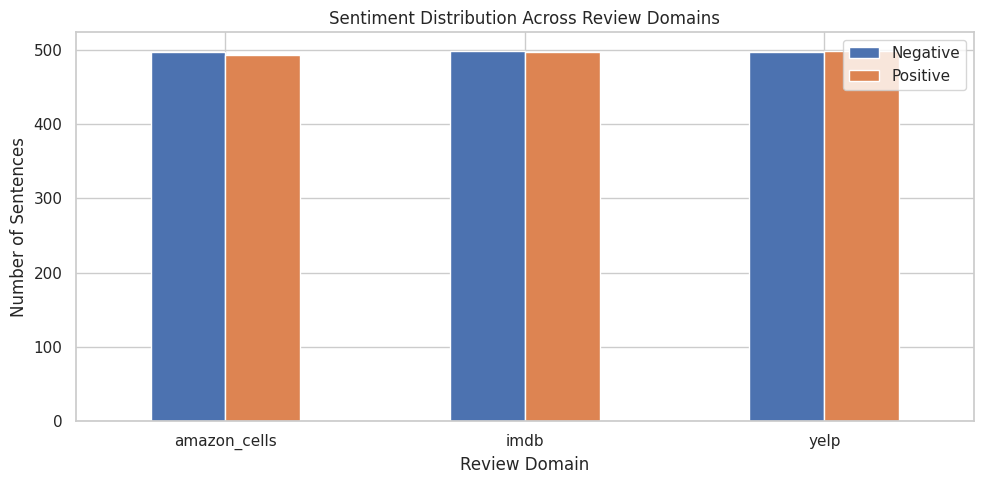

In [7]:
domain_sentiment = pd.crosstab(df_clean["domain"], df_clean["label"])
domain_sentiment = domain_sentiment.reindex(columns=[0, 1], fill_value=0)
domain_sentiment.columns = ["Negative", "Positive"]
display(domain_sentiment)

domain_sentiment.plot(kind="bar", figsize=(10, 5))
plt.title("Sentiment Distribution Across Review Domains")
plt.xlabel("Review Domain")
plt.ylabel("Number of Sentences")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

###### 6.3 Positive and Negative Examples
Display sample sentences from both sentiment classes.

In [8]:
print("POSITIVE SENTENCES")
for i, sentence in enumerate(
    df_clean.loc[df_clean["label"] == 1, "sentence"].sample(
        min(5, (df_clean["label"] == 1).sum()), random_state=RANDOM_STATE
    ), 1
):
    print(f"{i}. {sentence}")

print("\\nNEGATIVE SENTENCES")
for i, sentence in enumerate(
    df_clean.loc[df_clean["label"] == 0, "sentence"].sample(
        min(5, (df_clean["label"] == 0).sum()), random_state=RANDOM_STATE
    ), 1
):
    print(f"{i}. {sentence}")

POSITIVE SENTENCES
1. They are so easy to love, but even more easy to identify with.  
2. It does everything the description said it would.
3. Thanks again to Amazon for having the things I need for a good price!
4. It's a campy sort of film that's a joy to watch.  
5. They keep getting better and better (this is my third one and I've had numerous Palms too).
\nNEGATIVE SENTENCES
1. This film tries to be a serious and sophisticated thriller/horror flick and it fails miserably.  
2. This scene is very strong and unpleasant.  
3. We will not be coming back.
4. Just whatever you do, avoid "Groove" as its the antithesis of all that is good about Human Traffic.  
5. It's one of the most boring Horror movies from the 90's mainly because it starts slow and centers in a boring atmosphere.  


###### 6.4 Frequently Occurring Words
Count frequent words separately for positive and negative reviews. Important negation words such as `not`, `no` and `never` are retained because they can change sentiment.

Frequent positive words


,Word,Frequency
0,great,195
1,good,177
2,film,105
3,movie,86
4,phone,85
5,one,76
6,well,68
7,best,63
8,food,60
9,place,57


Frequent negative words


,Word,Frequency
0,not,247
1,bad,100
2,movie,96
3,phone,79
4,one,70
5,like,68
6,food,65
7,time,62
8,no,61
9,would,58


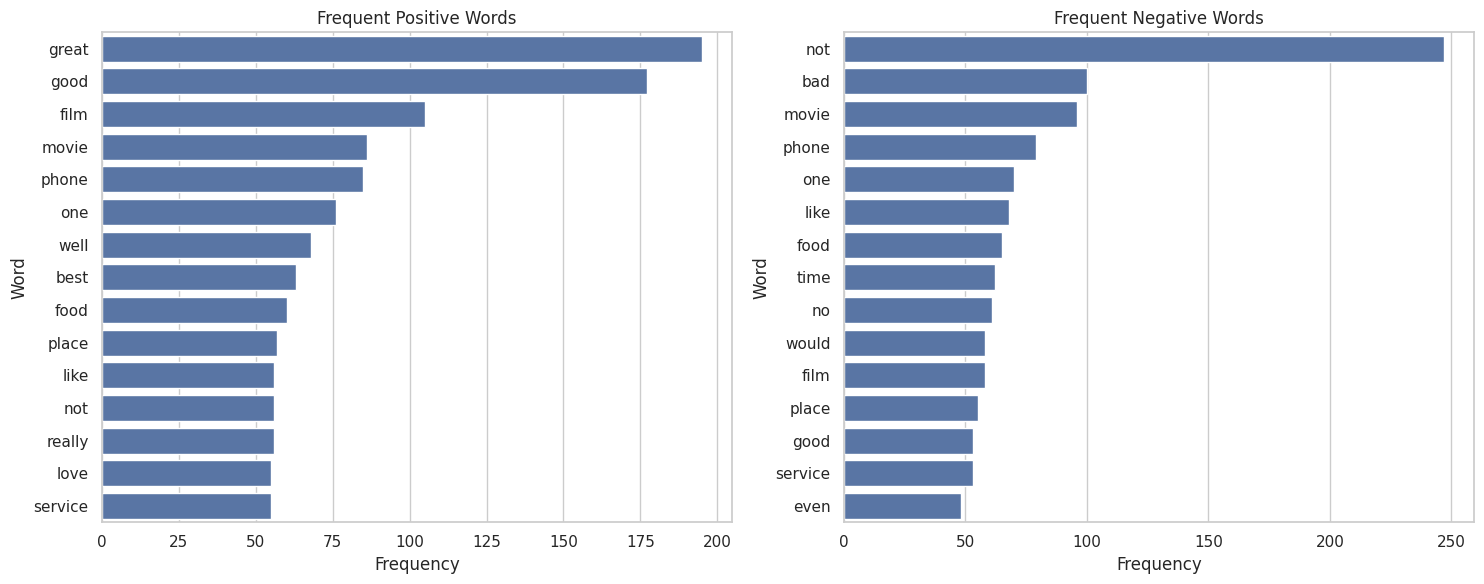

In [9]:
stop_words = set(stopwords.words("english"))
stop_words -= {"not", "no", "nor", "never"}

def get_frequent_words(text_series, top_n=15):
    words = []
    for sentence in text_series:
        words.extend(
            word for word in sentence.split()
            if word not in stop_words and len(word) > 1
        )
    return Counter(words).most_common(top_n)

positive_words = get_frequent_words(
    df_clean.loc[df_clean["label"] == 1, "clean_text"]
)
negative_words = get_frequent_words(
    df_clean.loc[df_clean["label"] == 0, "clean_text"]
)

print("Frequent positive words")
display(pd.DataFrame(positive_words, columns=["Word", "Frequency"]))
print("Frequent negative words")
display(pd.DataFrame(negative_words, columns=["Word", "Frequency"]))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, word_list, title in [
    (axes[0], positive_words, "Frequent Positive Words"),
    (axes[1], negative_words, "Frequent Negative Words")
]:
    word_df = pd.DataFrame(word_list, columns=["Word", "Frequency"])
    sns.barplot(data=word_df, x="Frequency", y="Word", ax=ax)
    ax.set_title(title)
plt.tight_layout()
plt.show()

###### 6.5 Sentence Length Analysis
Examine the distribution of sentence lengths.

,Word Count Statistics
count,2983.000000
mean,12.172310
std,8.108905
min,1.000000
25%,6.000000
50%,11.000000
75%,17.000000
max,74.000000


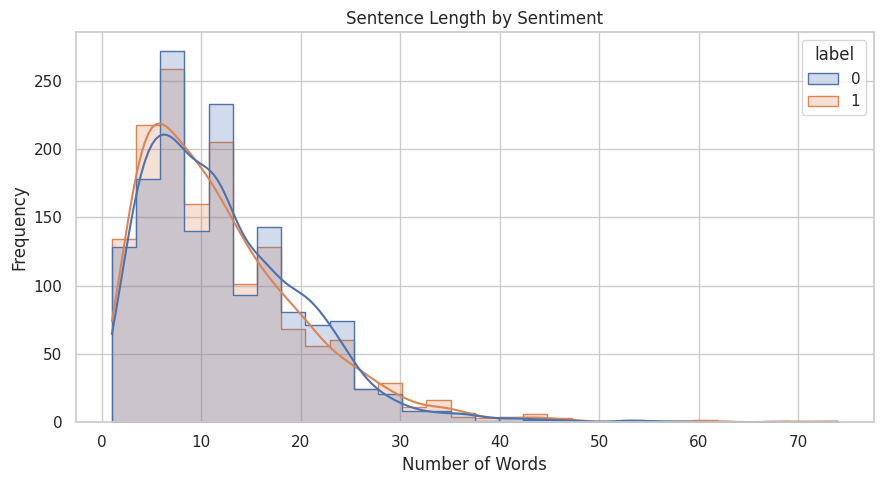

In [10]:
df_clean["word_count"] = df_clean["clean_text"].apply(lambda x: len(x.split()))
display(df_clean["word_count"].describe().to_frame("Word Count Statistics"))

sns.histplot(
    data=df_clean, x="word_count", hue="label",
    bins=30, element="step", kde=True
)
plt.title("Sentence Length by Sentiment")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

##### 7. Split the Dataset
Split the cleaned data into 80% training data and 20% testing data. Stratification preserves the class proportions in both sets.

In [11]:
X = df_clean["clean_text"]
y = df_clean["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Total samples:", len(X))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\\nTraining label distribution:")
display(y_train.value_counts().sort_index().rename(
    index={0: "Negative", 1: "Positive"}
).to_frame("Count"))

print("\\nTesting label distribution:")
display(y_test.value_counts().sort_index().rename(
    index={0: "Negative", 1: "Positive"}
).to_frame("Count"))

Total samples: 2983
Training samples: 2386
Testing samples: 597
\nTraining label distribution:


,Count
label,
Negative,1194
Positive,1192


\nTesting label distribution:


,Count
label,
Negative,299
Positive,298


##### 8. Feature Extraction – Bag of Words and TF-IDF
Bag of Words represents text using word occurrence counts. TF-IDF weights words according to their importance in a document relative to the collection. Vectorisers are fitted only on the training data to avoid data leakage.

In [12]:
bow_vectorizer = CountVectorizer(max_features=10000, ngram_range=(1, 2))
X_train_bow = bow_vectorizer.fit_transform(X_train)
X_test_bow = bow_vectorizer.transform(X_test)

tfidf_vectorizer = TfidfVectorizer(
    max_features=10000, ngram_range=(1, 2), sublinear_tf=True
)
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("BoW training matrix:", X_train_bow.shape)
print("BoW testing matrix:", X_test_bow.shape)
print("TF-IDF training matrix:", X_train_tfidf.shape)
print("TF-IDF testing matrix:", X_test_tfidf.shape)

print("\\nSample BoW vocabulary:")
print(list(bow_vectorizer.vocabulary_.keys())[:20])
print("\\nSample TF-IDF vocabulary:")
print(list(tfidf_vectorizer.vocabulary_.keys())[:20])

BoW training matrix: (2386, 10000)
BoW testing matrix: (597, 10000)
TF-IDF training matrix: (2386, 10000)
TF-IDF testing matrix: (597, 10000)
\nSample BoW vocabulary:
['about', '30', 'minutes', 'of', 'footage', 'is', 'wasted', 'to', 'show', 'mediocre', 'elderly', 'actors', 'awkwardly', 'gibberish', 'corny', 'enough', 'make', 'goth', 'almost', 'always']
\nSample TF-IDF vocabulary:
['about', '30', 'minutes', 'of', 'footage', 'is', 'wasted', 'to', 'show', 'mediocre', 'elderly', 'actors', 'awkwardly', 'gibberish', 'corny', 'enough', 'make', 'goth', 'almost', 'always']


##### 9. Train Machine Learning Models
Train and compare Logistic Regression and Linear Support Vector Machine (SVM) using both BoW and TF-IDF. Five-fold cross-validation is performed on the training set. The final test set is held out for evaluation.

In [13]:
models = {
    "BoW + Logistic Regression": Pipeline([
        ("vectorizer", CountVectorizer(max_features=10000, ngram_range=(1, 2))),
        ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),
    "TF-IDF + Logistic Regression": Pipeline([
        ("vectorizer", TfidfVectorizer(
            max_features=10000, ngram_range=(1, 2), sublinear_tf=True
        )),
        ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),
    "BoW + Linear SVM": Pipeline([
        ("vectorizer", CountVectorizer(max_features=10000, ngram_range=(1, 2))),
        ("classifier", LinearSVC(random_state=RANDOM_STATE))
    ]),
    "TF-IDF + Linear SVM": Pipeline([
        ("vectorizer", TfidfVectorizer(
            max_features=10000, ngram_range=(1, 2), sublinear_tf=True
        )),
        ("classifier", LinearSVC(random_state=RANDOM_STATE))
    ])
}

results = []
trained_models = {}

for name, model in models.items():
    print("Training:", name)

    cv_scores = cross_val_score(
        model, X_train, y_train,
        cv=5, scoring="f1_macro", n_jobs=-1
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "CV Mean F1": cv_scores.mean(),
        "CV F1 Std": cv_scores.std(),
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, average="macro", zero_division=0),
        "Recall": recall_score(y_test, predictions, average="macro", zero_division=0),
        "F1 Score": f1_score(y_test, predictions, average="macro", zero_division=0)
    })
    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values(
    by="CV Mean F1", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

Training: BoW + Logistic Regression
Training: TF-IDF + Logistic Regression
Training: BoW + Linear SVM
Training: TF-IDF + Linear SVM


,Model,CV Mean F1,CV F1 Std,Accuracy,Precision,Recall,F1 Score
0,TF-IDF + Linear SVM,0.8235,0.0052,0.8224,0.8225,0.8224,0.8224
1,BoW + Linear SVM,0.8164,0.0079,0.8040,0.8046,0.8040,0.8039
2,BoW + Logistic Regression,0.8147,0.0060,0.7990,0.7992,0.7990,0.7989
3,TF-IDF + Logistic Regression,0.8139,0.0052,0.7923,0.7926,0.7923,0.7922


##### 10. Evaluate and Compare Model Performance
Compare accuracy, precision, recall and F1-score on the held-out test set.

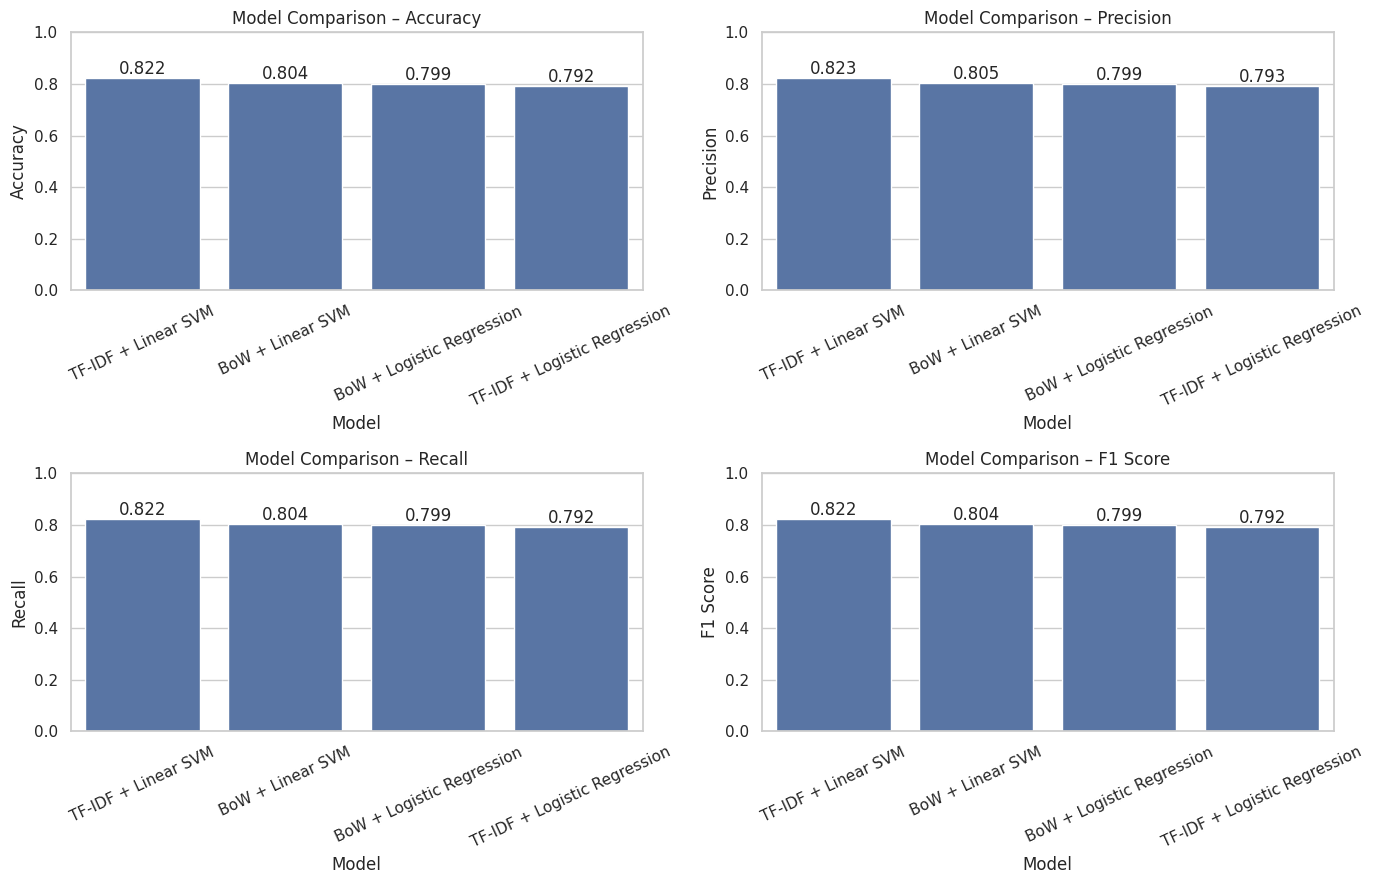

The model with the highest mean cross-validation F1-score is:
TF-IDF + Linear SVM


In [14]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, metric in zip(axes.flatten(), metrics):
    sns.barplot(data=results_df, x="Model", y=metric, ax=ax)
    ax.set_title(f"Model Comparison – {metric}")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=25)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f")
plt.tight_layout()
plt.show()

print("The model with the highest mean cross-validation F1-score is:")
print(results_df.iloc[0]["Model"])

##### 11. Detailed Evaluation of the Selected Model
Select the model using the highest mean cross-validation F1-score, then report its performance on the test set.

Selected model: TF-IDF + Linear SVM
\nClassification report:
              precision    recall  f1-score   support

    Negative     0.8185    0.8294    0.8239       299
    Positive     0.8265    0.8154    0.8209       298

    accuracy                         0.8224       597
   macro avg     0.8225    0.8224    0.8224       597
weighted avg     0.8225    0.8224    0.8224       597



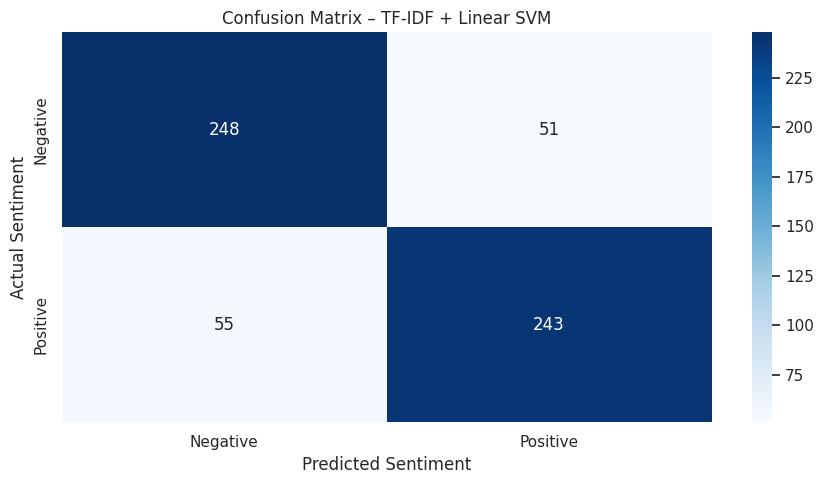

In [15]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
best_predictions = best_model.predict(X_test)

print("Selected model:", best_model_name)
print("\\nClassification report:")
print(classification_report(
    y_test, best_predictions,
    target_names=["Negative", "Positive"],
    digits=4,
    zero_division=0
))

cm = confusion_matrix(y_test, best_predictions, labels=[0, 1])
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)
plt.title(f"Confusion Matrix – {best_model_name}")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.tight_layout()
plt.show()

##### 12. Error Analysis
Inspect examples where the selected model predicted the wrong sentiment. This can help identify cases involving negation, mixed opinions, ambiguous wording or context.

In [16]:
error_analysis = pd.DataFrame({
    "Original Sentence": df_clean.loc[X_test.index, "sentence"].values,
    "Cleaned Sentence": X_test.values,
    "Actual Sentiment": y_test.map({0: "Negative", 1: "Positive"}).values,
    "Predicted Sentiment": pd.Series(best_predictions, index=X_test.index)
        .map({0: "Negative", 1: "Positive"}).values
}, index=X_test.index)

misclassified = error_analysis[
    error_analysis["Actual Sentiment"] != error_analysis["Predicted Sentiment"]
]

print("Number of misclassified sentences:", len(misclassified))
display(misclassified.head(20))

Number of misclassified sentences: 106


,Original Sentence,Cleaned Sentence,Actual Sentiment,Predicted Sentiment
985,The screen does get smudged easily because it ...,the screen does get smudged easily because it ...,Negative,Positive
2886,"And the drinks are WEAK, people!",and the drinks are weak people,Negative,Positive
791,I tried talking real loud but shouting on the ...,i tried talking real loud but shouting on the ...,Negative,Positive
1133,"You can't relate with them, hell you barely ca...",you can t relate with them hell you barely ca...,Negative,Positive
945,Buttons are too small.,buttons are too small,Negative,Positive
637,Very wind-resistant.,very wind resistant,Positive,Negative
2507,"Oh this is such a thing of beauty, this restau...",oh this is such a thing of beauty this restau...,Positive,Negative
1528,i wouldnt see this movie again for free.,i wouldnt see this movie again for free,Negative,Positive
2157,We also ordered the spinach and avocado salad;...,we also ordered the spinach and avocado salad ...,Negative,Positive
320,I ordered this product first and was unhappy w...,i ordered this product first and was unhappy w...,Negative,Positive


##### 13. Test the Model with New Sentences
Use the selected model to classify sentences that were not part of the training or test dataset. For Linear SVM, the model score is a decision score, not a calibrated probability.

In [17]:
def predict_sentiment(text):
    cleaned_text = preprocess_text(text)
    prediction = int(best_model.predict([cleaned_text])[0])

    result = {
        "Original Sentence": text,
        "Cleaned Sentence": cleaned_text,
        "Predicted Sentiment": "Positive" if prediction == 1 else "Negative"
    }

    classifier = best_model.named_steps["classifier"]

    if hasattr(best_model, "predict_proba"):
        probabilities = best_model.predict_proba([cleaned_text])[0]
        result["Score Type"] = "Predicted probability"
        result["Model Score"] = float(np.max(probabilities))
    elif hasattr(best_model, "decision_function"):
        score = float(best_model.decision_function([cleaned_text])[0])
        result["Score Type"] = "SVM decision score"
        result["Model Score"] = score
    else:
        result["Score Type"] = "Not available"
        result["Model Score"] = None

    return result

test_sentences = [
    "This product is absolutely amazing!",
    "The movie was terrible and boring.",
    "I really enjoyed the experience.",
    "The food was not good at all.",
    "The service was excellent and friendly.",
    "I would never recommend this product.",
    "The quality is acceptable but not impressive.",
    "I love this place!"
]

prediction_df = pd.DataFrame([
    predict_sentiment(sentence) for sentence in test_sentences
])
display(prediction_df)

,Original Sentence,Cleaned Sentence,Predicted Sentiment,Score Type,Model Score
0,This product is absolutely amazing!,this product is absolutely amazing,Positive,SVM decision score,0.466995
1,The movie was terrible and boring.,the movie was terrible and boring,Negative,SVM decision score,-1.218216
2,I really enjoyed the experience.,i really enjoyed the experience,Positive,SVM decision score,0.340656
3,The food was not good at all.,the food was not good at all,Negative,SVM decision score,-1.089446
4,The service was excellent and friendly.,the service was excellent and friendly,Positive,SVM decision score,0.814389
5,I would never recommend this product.,i would never recommend this product,Negative,SVM decision score,-0.003788
6,The quality is acceptable but not impressive.,the quality is acceptable but not impressive,Negative,SVM decision score,-0.320716
7,I love this place!,i love this place,Positive,SVM decision score,1.007853


##### 14. Save the Selected Model
Save the complete pipeline, including its text vectoriser and classifier, so it can be reused without retraining.

In [18]:
os.makedirs("outputs", exist_ok=True)

model_path = os.path.join("outputs", "sentiment_model.joblib")
joblib.dump(best_model, model_path)

print("Selected model saved to:", model_path)

Selected model saved to: outputs/sentiment_model.joblib


##### 15. Practical Summary

Complete the following observations after running all cells:

- **Dataset size:** Record the final number of rows and columns.
- **Preprocessing:** Note how lowercase conversion, punctuation removal and whitespace normalisation changed the sentences.
- **Frequent words:** Compare the common words in positive and negative reviews.
- **Feature extraction:** Compare the BoW and TF-IDF feature matrix dimensions.
- **Model performance:** Identify the model with the highest cross-validation F1-score and report its test metrics.
- **Error analysis:** Review misclassified sentences and identify possible reasons for incorrect predictions.
- **New sentence testing:** Check whether the predictions for the new sentences are reasonable.

##### 16. Learning Outcomes

After completing this practical, the following skills should have been practised:

1. Loading and inspecting a text dataset.
2. Cleaning and preprocessing text data.
3. Exploring sentiment labels and frequent words.
4. Splitting data into training and testing sets.
5. Converting text into BoW and TF-IDF numerical features.
6. Training Logistic Regression and Linear SVM classifiers.
7. Evaluating models using accuracy, precision, recall, F1-score and a confusion matrix.
8. Applying a trained model to new text.

##### 17. References

- UCI Machine Learning Repository: [Sentiment Labelled Sentences](https://archive.ics.uci.edu/dataset/331/sentiment+labelled+sentences)
- Scikit-learn documentation: [https://scikit-learn.org/stable/](https://scikit-learn.org/stable/)
- NLTK documentation: [https://www.nltk.org/](https://www.nltk.org/)